# 04 · Transformación de datos

**Objetivo:** dejar los datos listos para entrenar los tres modelos:
1. Crear las **variables nuevas** decididas en el EDA.
2. Construir los **tres objetivos**: impago (PD), exposición (EAD) y pérdida (LGD).
3. **Transformar** las variables numéricas (recortes y logaritmos) y decidir cómo se **codifican** las categóricas.
4. Reunir todo en una **función reutilizable**, para aplicar exactamente lo mismo a validación y a la API.
5. Guardar un **tablón** (tabla final de modelización) para cada modelo.

**Cómo se trabaja** (igual que en los notebooks 02 y 03): observación → decisión → aplicación. Cada decisión aparece en un recuadro **Decisión Dx** con qué se hace, por qué y qué alternativas se descartaron.

> **Regla general:** todos los valores que se aprenden de los datos (por ejemplo, los límites de los recortes) se calculan **solo con entrenamiento** y se guardan, para aplicarlos sin recalcular a validación y a la API.

<a id="s0"></a>

## Registro de decisiones

| # | Tema | Decisión | Motivo principal |
|---|---|---|---|
| D1 | Variables nuevas | Crear `ratio_principal_ingresos` y `antiguedad_historial` | Decididas en el EDA (D10 y D18 del notebook 03) |
| D2 | Objetivo PD | `impago` = 1 si `Charged Off`, 0 si `Fully Paid` | Solo quedan préstamos terminados (notebook 01) |
| D3 | Objetivo EAD | (principal − amortizado) / principal, solo impagados | Fracción del importe pendiente al impagar; siempre entre 0 y 1 |
| D4 | Objetivo LGD | 1 − recuperado / pendiente, limitada a 0–1; fuera los 2 préstamos sin deuda pendiente | 395 recuperaciones superan la deuda pendiente (LGD negativa) |
| D5 | Recuperaciones por año | Usar todos los años para la LGD | La tasa media de recuperación es estable; cambia la forma de recuperar, no la cantidad |
| D6 | Referencias de EAD y LGD | Mediana por plazo como *benchmark* (MAE 0,198 y 0,092) | Es el listón que deben superar los modelos de los notebooks 06 y 07 |
| D7 | Recortes | Recortar por arriba al percentil 99,9 de entrenamiento las variables con cola larga; `num_consultas_6meses` en 4 | Pocos casos extremos no deben dominar una regresión logística |
| D8 | Logaritmos | `log1p` en `ingresos`, `num_hipotecas` y `antiguedad_historial`; **no** en `saldo_revolving` | Solo donde el logaritmo mejora el ajuste; en el saldo lo empeora |
| D9 | Categóricas | *One-hot* dentro del *pipeline* del notebook 05 | Mejor AUC que el WoE y más fácil de interpretar |
| D10 | Escalado | Estandarizar dentro del *pipeline* del notebook 05 | Necesario para la regularización L1; se aprende solo en cada partición de entrenamiento |
| D11 | Función reutilizable | `transformar(datos, parametros)` aplica D1, D7 y D8 | El mismo código para entrenamiento, validación y API |
| D12 | Tablones | Uno por modelo: PD (todos), EAD (impagados) y LGD (impagados con deuda pendiente) | Cada modelo se entrena con una población distinta |
| D13 | Guardado | `tablon_pd.pkl`, `tablon_ead.pkl`, `tablon_lgd.pkl` y `parametros_transformacion.pkl` | Reproducibilidad y mismo tratamiento en validación y en la API |

## Índice

- [Registro de decisiones](#s0)
- [1 · Importar librerías](#s1)
- [2 · Cargar los datos](#s2)
- [3 · Variables nuevas (D1)](#s3)
- [4 · Objetivos](#s4)
  - [4.1 · PD: impago (D2)](#s4-1)
  - [4.2 · EAD: exposición en el impago (D3)](#s4-2)
  - [4.3 · LGD: pérdida en caso de impago (D4)](#s4-3)
  - [4.4 · ¿Están completas las recuperaciones? (D5)](#s4-4)
  - [4.5 · Referencias para EAD y LGD (D6)](#s4-5)
- [5 · Transformaciones numéricas](#s5)
  - [5.1 · Recortes de valores extremos (D7)](#s5-1)
  - [5.2 · Logaritmos (D8)](#s5-2)
- [6 · Codificación de las categóricas (D9)](#s6)
- [7 · Escalado (D10)](#s7)
- [8 · Función de transformación reutilizable (D11)](#s8)
- [9 · Tablones de modelización (D12)](#s9)
- [10 · Guardar (D13)](#s10)
- [11 · Resumen y próximos pasos](#s11)

> Cada sección empieza con una **franja azul**. Debajo de cada resultado hay una explicación de **qué se hace** y **qué se observa**.

<a id="s1"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">1 · IMPORTAR LIBRERÍAS</span>

</div>

In [1]:
# --- Librerías ------------------------------------------------------------
from pathlib import Path          # rutas de archivos independientes del sistema operativo
import numpy as np                # cálculo numérico
import pandas as pd               # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt   # gráficos
import seaborn as sns             # gráficos estadísticos sobre matplotlib

# Modelos rápidos de comparación (no son los modelos finales)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# --- Opciones de visualización --------------------------------------------
pd.set_option('display.float_format', lambda x: '%.3f' % x)  # sin notación científica
pd.set_option('display.max_columns', 60)                     # mostrar todas las columnas
np.set_printoptions(suppress=True)
sns.set_theme(style='whitegrid')                             # estilo de los gráficos

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


<a id="s2"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">2 · CARGAR LOS DATOS</span>

</div>

In [2]:
# Rutas de entrada (relativas a la carpeta de este notebook: 03_notebooks/es)
RUTA_DATOS = Path('../../02_datos/03_Entrenamiento')
RUTA_TRAIN_EDA = RUTA_DATOS / 'train_eda.pkl'
RUTA_PARAMETROS_EDA = RUTA_DATOS / 'parametros_eda.pkl'

# Conjunto de entrenamiento del notebook 03 y parámetros del EDA (listas de variables por papel)
df = pd.read_pickle(RUTA_TRAIN_EDA)
PARAMETROS_EDA = pd.read_pickle(RUTA_PARAMETROS_EDA)

print(f"Préstamos: {df.shape[0]:,} · Columnas: {df.shape[1]}")
for clave in ['CANDIDATAS_CATEGORICAS', 'CANDIDATAS_NUMERICAS', 'CANDIDATAS_NUEVAS', 'BENCHMARK']:
    print(f"{clave:24s}: {PARAMETROS_EDA[clave]}")

Préstamos: 443,405 · Columnas: 25
CANDIDATAS_CATEGORICAS  : ['antigüedad_empleo', 'vivienda', 'finalidad', 'sector_empleo']
CANDIDATAS_NUMERICAS    : ['num_cuotas', 'ingresos', 'dti', 'fico', 'num_lineas_credito', 'num_hipotecas', 'saldo_revolving', 'porc_uso_tarjetas', 'num_consultas_6meses']
CANDIDATAS_NUEVAS       : ['ratio_principal_ingresos', 'antiguedad_historial']
BENCHMARK               : ['rating', 'subrating', 'tipo_interes', 'imp_cuota', 'ingresos_verificados']


**Qué se hace:** se cargan el conjunto de entrenamiento que guardó el notebook 03 y sus parámetros, y se muestran las listas de variables por papel.

**Qué se observa:** **443.405 préstamos y 25 columnas**. Las 15 variables candidatas son 4 categóricas, 9 numéricas y 2 nuevas que se crean en este notebook. Las 5 de *benchmark* (la evaluación de Lending Club) se conservan solo para comparar.

<a id="s3"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">3 · VARIABLES NUEVAS (D1)</span>

</div>

En el EDA se decidió crear dos variables (D10 y D18 del notebook 03):
- **`ratio_principal_ingresos`** = importe del préstamo / ingresos anuales: qué parte de un año de ingresos supone el préstamo. El importe solo no separaba el riesgo; en relación con los ingresos, sí.
- **`antiguedad_historial`** = años entre el primer crédito del cliente y la concesión del préstamo. Una fecha no sirve como variable de un modelo; la duración del historial, sí.

In [3]:
# Importe del préstamo en relación con los ingresos anuales
df['ratio_principal_ingresos'] = df['principal'] / df['ingresos']

# Años de historial de crédito al pedir el préstamo (365,25 días por año para contar los bisiestos)
df['antiguedad_historial'] = (df['fecha_concesion'] - df['fecha_primer_credito']).dt.days / 365.25

# Comprobaciones: sin nulos, sin infinitos y sin valores negativos
nuevas = df[['ratio_principal_ingresos', 'antiguedad_historial']]
assert nuevas.notna().all().all(), "Hay nulos en las variables nuevas"
assert np.isfinite(nuevas).all().all(), "Hay infinitos en las variables nuevas"
assert (nuevas >= 0).all().all(), "Hay valores negativos en las variables nuevas"
nuevas.describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
ratio_principal_ingresos,443405.000,0.204,0.108,0.000,0.027,0.189,0.460,0.713
antiguedad_historial,443405.000,16.225,7.537,2.998,3.923,14.746,39.669,71.001


**Qué se hace:** se crean las dos variables y se comprueba que no tienen nulos, infinitos ni valores negativos (por ejemplo, un primer crédito posterior a la concesión).

**Qué se observa:** las dos son válidas en todos los préstamos. El préstamo supone de mediana el **19 %** de los ingresos anuales (máximo 71 %), y la mediana del historial de crédito es de **15 años** (mínimo 3, máximo 71).

> **Decisión D1 · Crear `ratio_principal_ingresos` y `antiguedad_historial` a partir de los datos originales.**
> - **Por qué ahora:** se calculan **antes** de los recortes y los logaritmos de la sección 5, con los valores reales de importe, ingresos y fechas.
> - **En la API:** el formulario pide el importe, los ingresos y el año del primer crédito; las dos variables se calculan solas con la misma función (sección 8).

<a id="s4"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">4 · OBJETIVOS</span>

</div>

Cada modelo predice algo distinto y se entrena con una población distinta:

| Modelo | Qué predice | Con qué préstamos se entrena |
|---|---|---|
| **PD** | ¿Impagará? (0 / 1) | Todos |
| **EAD** | Qué fracción del importe quedará pendiente si impaga (0–1) | Solo los impagados |
| **LGD** | Qué fracción de esa deuda pendiente se perderá (0–1) | Solo los impagados con deuda pendiente |

La **pérdida esperada** de un préstamo es PD × EAD × LGD × importe.

<a id="s4-1"></a>

### 4.1 · PD: impago (D2)

In [4]:
# Objetivo de PD: 1 si el préstamo terminó en impago ('Charged Off'), 0 si se devolvió completo
df['impago'] = df['estado'].eq('Charged Off').astype(int)

# Comprobación: solo hay dos estados posibles
assert set(df['estado'].unique()) == {'Fully Paid', 'Charged Off'}, "Hay estados inesperados"
df['impago'].value_counts().to_frame('n_prestamos').assign(pct=lambda t: t['n_prestamos'] / len(df) * 100)

,n_prestamos,pct
impago,,
0,377567,85.152
1,65838,14.848


**Qué se hace:** se crea el objetivo de la PD (`impago`) y se comprueba que no hay estados distintos de *Fully Paid* y *Charged Off*.

**Qué se observa:** **65.838 impagos (14,8 %)** frente a 377.567 préstamos devueltos.

> **Decisión D2 · `impago` = 1 si `estado` es `Charged Off` y 0 si es `Fully Paid`.**
> - **Por qué:** tras el notebook 01 solo quedan préstamos terminados, así que no hay estados intermedios (`Current`, `Late`...) que obliguen a elegir una definición de impago.

<a id="s4-2"></a>

### 4.2 · EAD: exposición en el impago (D3)

**EAD** = (principal − importe amortizado) / principal: qué fracción del importe concedido **quedaba por devolver** cuando el cliente dejó de pagar.

In [5]:
# Solo los préstamos impagados
impagados = df[df['impago'] == 1].copy()

# Deuda pendiente al impagar y EAD como fracción del importe
impagados['pendiente'] = impagados['principal'] - impagados['imp_amortizado']
impagados['ead'] = impagados['pendiente'] / impagados['principal']

# Comprobaciones: la EAD debe estar entre 0 y 1
print(f"Impagados: {len(impagados):,}")
print(f"EAD < 0: {(impagados['ead'] < 0).sum()} · EAD > 1: {(impagados['ead'] > 1).sum()} · EAD = 0: {(impagados['ead'] == 0).sum()}")
impagados['ead'].describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).to_frame().T

Impagados: 65,838
EAD < 0: 0 · EAD > 1: 0 · EAD = 0: 2


,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,max
ead,65838.000,0.593,0.241,0.000,0.062,0.237,0.417,0.624,0.790,0.890,0.979,1.000


**Qué se hace:** se calcula la deuda pendiente y la EAD de cada préstamo impagado, y se comprueba que la EAD está entre 0 y 1.

**Qué se observa:**
- **Todas las EAD están entre 0 y 1**: ningún cliente devolvió más del importe ni tiene amortizaciones negativas. Solo **2** tienen EAD = 0: devolvieron todo el principal pero dejaron intereses sin pagar.
- De media quedaba por devolver el **59 %** del importe (mediana 62 %), con mucha dispersión (del 6 % en el percentil 1 al 98 % en el 99).

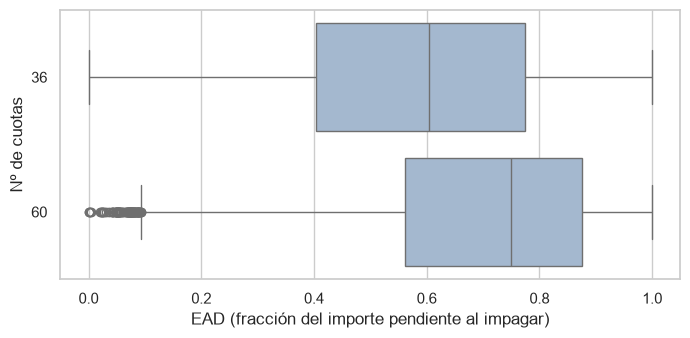

,count,mean,50%
num_cuotas,,,
36,57861.000,0.579,0.605
60,7977.000,0.697,0.749


In [6]:
# EAD por plazo: con 60 cuotas el préstamo se amortiza más despacio
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=impagados, x='ead', y=impagados['num_cuotas'].astype(str), ax=ax, color='#9db8d6')
ax.set_xlabel('EAD (fracción del importe pendiente al impagar)')
ax.set_ylabel('Nº de cuotas')
plt.show()
impagados.groupby('num_cuotas')['ead'].describe()[['count', 'mean', '50%']]

**Qué se hace:** distribución de la EAD según el plazo del préstamo (diagrama de caja: la caja va del percentil 25 al 75 y la raya es la mediana).

**Qué se observa:** con **60 cuotas** queda más deuda pendiente al impagar (mediana **0,75** frente a **0,61** con 36), porque cada cuota amortiza una parte más pequeña del importe. Es la variable que más se relaciona con la EAD (D21 del notebook 03).

> **Decisión D3 · EAD = (principal − importe amortizado) / principal, calculada solo para los impagados.**
> - **Por qué como fracción y no en dólares:** así no depende del tamaño del préstamo y se combina directamente en la fórmula PD × EAD × LGD × importe.
> - **Los 2 casos con EAD = 0 se conservan:** son reales (deben intereses, no principal) y no afectan al modelo.

<a id="s4-3"></a>

### 4.3 · LGD: pérdida en caso de impago (D4)

**LGD** = 1 − importe recuperado / deuda pendiente: qué fracción de la deuda pendiente **no se recupera nunca**. Su complemento es la **tasa de recuperación** (recuperado / pendiente).

In [7]:
# Tasa de recuperación: fracción de la deuda pendiente que se recuperó tras el impago
# (sin deuda pendiente no se puede calcular: quedan como nulo)
impagados['tasa_recuperacion'] = (impagados['imp_recuperado'] / impagados['pendiente']).where(impagados['pendiente'] > 0)

# Casos especiales antes de calcular la LGD
print(f"Sin deuda pendiente (no se puede calcular):        {impagados['tasa_recuperacion'].isna().sum()}")
print(f"Recuperado > pendiente (LGD negativa sin límite):  {(impagados['tasa_recuperacion'] > 1).sum()}")
print(f"Nada recuperado (LGD = 1):                         {(impagados['tasa_recuperacion'] == 0).sum():,}")

# Los casos con recuperación mayor que la deuda: ¿cuánto se pasan?
impagados.loc[impagados['tasa_recuperacion'] > 1, 'tasa_recuperacion'].describe(percentiles=[0.5, 0.9, 0.99]).to_frame().T

Sin deuda pendiente (no se puede calcular):        2
Recuperado > pendiente (LGD negativa sin límite):  395
Nada recuperado (LGD = 1):                         13,409


,count,mean,std,min,50%,90%,99%,max
tasa_recuperacion,395.000,1.193,1.987,1.000,1.047,1.100,1.480,35.426


**Qué se hace:** se calcula la tasa de recuperación y se cuentan los casos especiales: sin deuda pendiente, con más recuperado que deuda y sin ninguna recuperación.

**Qué se observa:**
- **2 préstamos** no tienen deuda pendiente (son los de EAD = 0): su LGD no se puede calcular.
- **395 préstamos (0,6 %)** recuperaron **más** de lo que debían; la mediana de esos casos es poco más de 1, pero algunos llegan a 35 veces la deuda. Probablemente la recuperación incluye intereses y comisiones de cobro, o son errores de registro. Ya se detectaron en el notebook 02 (D24).
- En unos **13.400 impagos** no se recuperó nada (LGD = 1).

,count,mean,std,min,1%,10%,25%,50%,75%,90%,max
lgd,65836.000,0.869,0.148,0.000,0.323,0.759,0.848,0.895,0.999,1.000,1.000


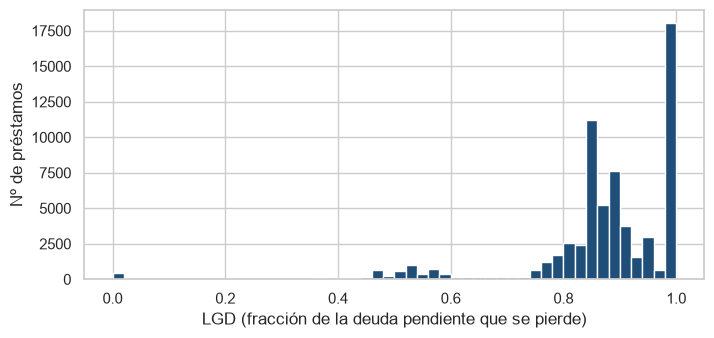

In [8]:
# LGD limitada a 0–1 (D24 del notebook 02): recuperar más de lo debido cuenta como pérdida 0
impagados['lgd'] = (1 - impagados['tasa_recuperacion']).clip(0, 1)

display(impagados['lgd'].describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9]).to_frame().T)

# Histograma de la LGD
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(impagados['lgd'].dropna(), bins=50, color='#1f4e79')
ax.set_xlabel('LGD (fracción de la deuda pendiente que se pierde)')
ax.set_ylabel('Nº de préstamos')
plt.show()

**Qué se hace:** se calcula la LGD limitada al rango 0–1 y se muestra su distribución.

**Qué se observa:** la LGD es **muy alta**: de media se pierde el **87 %** de la deuda pendiente (mediana 90 %), en uno de cada cinco impagos se pierde todo y en 413 (los que recuperaron todo o más) la pérdida es 0. Son préstamos **sin garantía**: no hay ningún bien que embargar.

> **Decisión D4 · LGD = 1 − recuperado / pendiente, limitada a 0–1; se excluyen los 2 préstamos sin deuda pendiente.**
> - **Por qué limitar:** una pérdida negativa (ganar dinero con un impago) no tiene sentido como objetivo y los pocos casos extremos (hasta 35 veces la deuda) distorsionarían el modelo. Se conservan con LGD = 0, que es su valor real a efectos de riesgo.
> - **Por qué excluir los 2 sin deuda pendiente:** la LGD es 0 / 0, no está definida.
> - **Alternativa descartada:** eliminar los 395 casos con recuperación > deuda. Son reales en la parte que importa (se recuperó todo) y eliminarlos sesgaría la LGD al alza.

<a id="s4-4"></a>

### 4.4 · ¿Están completas las recuperaciones? (D5)

En el notebook 03 (D21) se vio que los impagados **sin ninguna recuperación** pasan del 2 % en 2012 al 28 % en 2015. La hipótesis era que en la fecha de corte del dataset (finales de 2018) las recuperaciones de los impagos recientes aún no habían terminado. Si fuera así, la LGD de 2014–2015 estaría **sobrestimada**. Aquí se comprueba.

In [9]:
# Por año de concesión: % sin recuperación, tasa de recuperación media (todos y solo los que recuperan algo) y LGD media
anio_impago = impagados['fecha_concesion'].dt.year
recuperaciones = pd.DataFrame({
    'n_impagados': impagados.groupby(anio_impago).size(),
    '%_sin_recuperacion': (impagados['tasa_recuperacion'] == 0).groupby(anio_impago).mean() * 100,
    'recuperacion_media': impagados['tasa_recuperacion'].clip(upper=1).groupby(anio_impago).mean(),
    'recuperacion_media_si_recupera': impagados.loc[impagados['tasa_recuperacion'] > 0, 'tasa_recuperacion'].clip(upper=1).groupby(anio_impago).mean(),
    'lgd_media': impagados['lgd'].groupby(anio_impago).mean(),
})
recuperaciones

,n_impagados,%_sin_recuperacion,recuperacion_media,recuperacion_media_si_recupera,lgd_media
fecha_concesion,,,,,
2012,6047,2.166,0.114,0.117,0.886
2013,14771,8.388,0.133,0.145,0.867
2014,15581,24.472,0.135,0.179,0.865
2015,29439,27.943,0.131,0.182,0.869


**Qué se hace:** para cada año de concesión, nº de impagados, % sin ninguna recuperación, tasa de recuperación media (de todos y solo de los que recuperan algo) y LGD media.

**Qué se observa:** el resultado **no apoya** la hipótesis de recuperaciones incompletas:
- El % sin recuperación sube del **2 %** al **28 %**, pero los que sí recuperan algo recuperan **más** (del 12 % al 18 % de la deuda).
- El efecto se compensa: la **recuperación media** de todos los impagados y la **LGD media** son prácticamente iguales todos los años (LGD **0,87–0,89**).

La explicación más coherente (inferida, el dataset no lo documenta) es que **cambió la forma de recuperar**: en los años recientes, una parte de las deudas se recupera de golpe (por ejemplo, vendiéndolas a agencias de cobro) y el resto no se persigue, en lugar de recuperar un poco de todas. Lo que importa para la LGD, la pérdida media, no cambia.

> **Decisión D5 · Usar los impagados de todos los años (2012–2015) para la LGD.**
> - **Por qué:** la LGD media es estable entre años, así que no hay señal de que las cohortes recientes estén incompletas. Quedarse solo con 2012–2013 reduciría los datos a un tercio sin ganar fiabilidad.
> - **Corrige la hipótesis de D21 del notebook 03**, que se planteó solo con el % sin recuperación.
> - **Consecuencia para el notebook 07:** la LGD tiene dos "modos" (recuperar 0 o recuperar algo). Un modelo de regresión normal predecirá valores cercanos a la media; conviene evaluarlo con cuidado.

<a id="s4-5"></a>

### 4.5 · Referencias para EAD y LGD (D6)

Antes de entrenar un modelo conviene saber qué error se obtiene **sin modelo**, prediciendo siempre un valor fijo. Es el **listón** (*benchmark*) que el modelo debe superar para que merezca la pena. Se mide con el **MAE** (*Mean Absolute Error*, error absoluto medio): la diferencia media, en valor absoluto, entre lo predicho y lo real.

In [10]:
# Tablas de EAD y LGD (la LGD sin los 2 préstamos sin deuda pendiente)
ead = impagados['ead']
lgd = impagados['lgd'].dropna()

def mae(real, prediccion):
    '''Error absoluto medio entre dos series.'''
    return (real - prediccion).abs().mean()

# Predicciones sin modelo: la media, la mediana y la mediana de cada plazo (36 / 60 cuotas)
referencias = pd.DataFrame({
    'EAD': [mae(ead, ead.mean()), mae(ead, ead.median()),
            mae(ead, ead.groupby(impagados['num_cuotas']).transform('median'))],
    'LGD': [mae(lgd, lgd.mean()), mae(lgd, lgd.median()),
            mae(lgd, lgd.groupby(impagados.loc[lgd.index, 'num_cuotas']).transform('median'))],
}, index=['siempre la media', 'siempre la mediana', 'mediana de cada plazo'])
referencias

,EAD,LGD
siempre la media,0.202,0.094
siempre la mediana,0.201,0.093
mediana de cada plazo,0.198,0.092


**Qué se hace:** MAE de tres predicciones sin modelo: siempre la media, siempre la mediana y la mediana de cada plazo. La mediana minimiza el MAE, por eso se prueba además de la media.

**Qué se observa:**
- **EAD:** sin modelo se comete un error medio de unos **0,20** (20 puntos del importe). Usar la mediana de cada plazo lo baja un poco, a **0,198**.
- **LGD:** el error sin modelo ya es pequeño, **0,092**, porque casi todas las LGD están entre 0,8 y 1. Será difícil mejorarlo mucho.
- Como referencia, los modelos de la versión anterior del proyecto (con otros datos) tenían MAE de 0,160 (EAD) y 0,089 (LGD): la mejora de la LGD sobre "no usar modelo" era muy pequeña.

> **Decisión D6 · Usar la mediana de cada plazo como *benchmark* de la EAD (MAE ≈ 0,198) y de la LGD (MAE ≈ 0,092).**
> - **Por qué:** es la predicción más sencilla que ya usa algo de información. Un modelo de EAD o LGD solo merece la pena si baja claramente de esos valores en validación.
> - **Para la demo:** si el modelo de LGD no mejora claramente, puede bastar con una LGD fija por plazo, más fácil de explicar.

<a id="s5"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">5 · TRANSFORMACIONES NUMÉRICAS</span>

</div>

La **regresión logística** (el modelo previsto para la PD) supone que cada variable numérica se relaciona con el riesgo **en línea recta** (en la escala del *log-odds*) y es sensible a los **valores extremos**: un cliente con 8,9 millones de ingresos pesa en el ajuste tanto como cientos de clientes normales. Dos transformaciones lo corrigen:
1. **Recortar** (*winsorizar*) los valores extremos a un límite.
2. Aplicar el **logaritmo** a las variables muy asimétricas.

Los modelos de **árboles** no necesitan ninguna de las dos (solo les importa el orden de los valores), así que estas transformaciones no les perjudican.

<a id="s5-1"></a>

### 5.1 · Recortes de valores extremos (D7)

In [11]:
# Variables con cola larga por arriba (las acotadas por Lending Club, fico y dti, no se recortan)
VARIABLES_RECORTE = ['ingresos', 'num_lineas_credito', 'num_hipotecas', 'saldo_revolving',
                     'porc_uso_tarjetas', 'ratio_principal_ingresos', 'antiguedad_historial']

# Límite superior: percentil 99,9 de entrenamiento; num_consultas_6meses en 4 (D16 del notebook 03)
TOPES = {v: float(df[v].quantile(0.999)) for v in VARIABLES_RECORTE}
TOPES['num_consultas_6meses'] = 4.0

# Tabla: percentil 99, límite, máximo y nº de préstamos afectados por el recorte
pd.DataFrame({
    'p99': {v: df[v].quantile(0.99) for v in TOPES},
    'limite': TOPES,
    'maximo': {v: df[v].max() for v in TOPES},
    'n_recortados': {v: int((df[v] > TOPES[v]).sum()) for v in TOPES},
})

,p99,limite,maximo,n_recortados
ingresos,250000.000,550000.000,8900060.000,414
num_lineas_credito,28.000,38.000,84.000,395
num_hipotecas,8.000,12.000,47.000,440
saldo_revolving,89095.360,257567.552,2904836.000,444
porc_uso_tarjetas,101.000,109.400,318.200,441
ratio_principal_ingresos,0.460,0.500,0.713,57
antiguedad_historial,39.669,49.338,71.001,444
num_consultas_6meses,4.000,4.000,8.000,2338


**Qué se hace:** se calcula el límite superior de cada variable con cola larga (percentil 99,9 de entrenamiento; 4 para las consultas) y cuántos préstamos lo superan.

**Qué se observa:**
- Los máximos están **muy lejos** del resto: ingresos de 8,9 millones con un límite de 550.000; saldo revolving de 2,9 millones con un límite de unos 258.000; 47 hipotecas con un límite de 12.
- El recorte afecta a muy pocos préstamos (unos 400–450 por variable, el 0,1 %; 57 en el ratio), salvo las consultas, donde se agrupan los clientes con 5 o más (2.338).

> **Decisión D7 · Recortar por arriba al percentil 99,9 de entrenamiento `ingresos`, `num_lineas_credito`, `num_hipotecas`, `saldo_revolving`, `porc_uso_tarjetas`, `ratio_principal_ingresos` y `antiguedad_historial`; `num_consultas_6meses` en 4.**
> - **Por qué recortar y no eliminar:** los extremos son clientes reales (notebook 02, D16). Recortados siguen en el modelo como "muy alto", sin dominar el ajuste.
> - **Por qué 99,9 y no 99:** afecta solo al 0,1 % de los préstamos. En `num_hipotecas` sustituye el límite de 8 (percentil 99) propuesto en el notebook 03 (D13), porque el logaritmo de la sección 5.2 ya suaviza los valores altos.
> - **`fico` y `dti` no se recortan:** ya están acotados por la política de Lending Club (FICO ≥ 662, DTI < 40).
> - **En la API:** los mismos límites se aplican a lo que escriba el usuario, así que un valor fuera de rango no producirá predicciones absurdas.

In [12]:
# Aplicar los recortes
for v, tope in TOPES.items():
    df[v] = df[v].clip(upper=tope)

# Comprobación: ninguna variable supera su límite
assert all((df[v] <= tope).all() for v, tope in TOPES.items()), "Algún valor supera su límite"
print("✅ Recortes aplicados")

✅ Recortes aplicados


<a id="s5-2"></a>

### 5.2 · Logaritmos (D8)

El **logaritmo** comprime los valores altos: la diferencia entre 20.000 y 40.000 $ de ingresos pesa lo mismo que entre 100.000 y 200.000 $. Se usa `log1p(x)` = ln(1 + x), que funciona también con ceros.

Para decidir en qué variables aplicarlo **no basta con que sean asimétricas**: hay que comprobar si mejora la relación con el impago. Se usan dos comprobaciones:
1. **Linealidad:** se divide la variable en 20 tramos y se compara su *log-odds* de impago, ln(tasa / (1 − tasa)), con el valor medio del tramo. Si los puntos forman una recta, la regresión logística la aprovecha bien.
2. **Log-loss** de una regresión logística con esa sola variable: mide lo lejos que están las probabilidades predichas de lo que ocurrió. Más bajo = mejor.

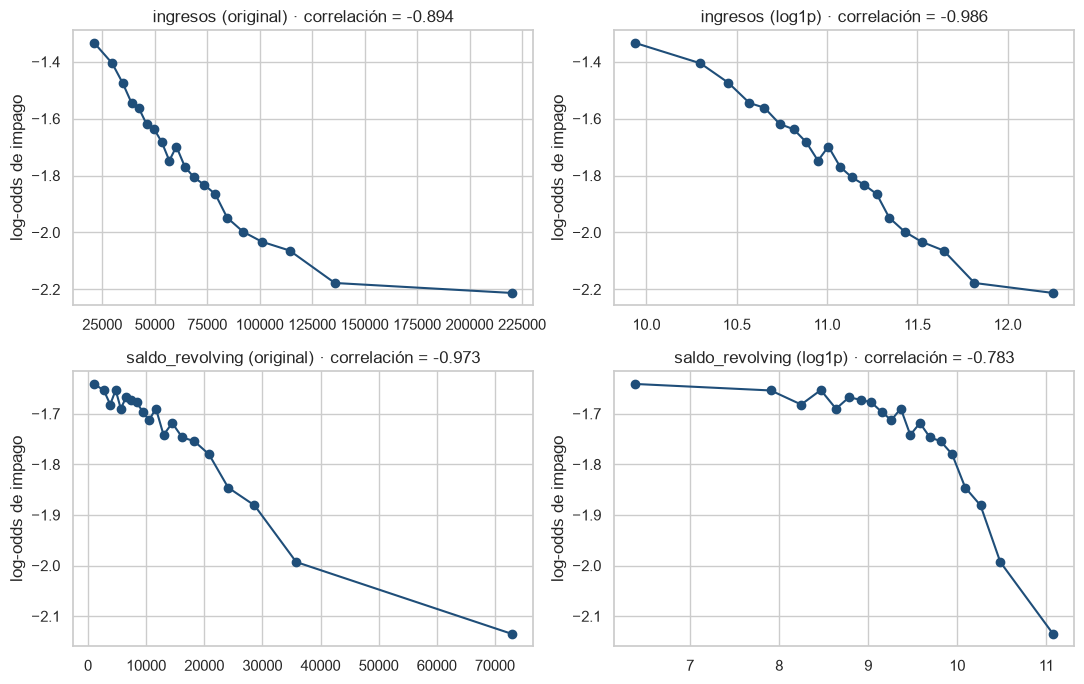

In [13]:
impago = df['impago']   # objetivo de PD (alias corto)

def logit_por_tramo(serie, n_tramos=20):
    '''Valor medio y log-odds de impago de cada tramo (mismo nº de préstamos por tramo).'''
    tramos = pd.qcut(serie, n_tramos, duplicates='drop')
    tasa = impago.groupby(tramos, observed=True).mean()
    return serie.groupby(tramos, observed=True).mean(), np.log(tasa / (1 - tasa))

# Gráficos: log-odds frente a la variable sin transformar (izquierda) y con logaritmo (derecha)
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for fila, v in enumerate(['ingresos', 'saldo_revolving']):
    for col, (nombre, serie) in enumerate([('original', df[v]), ('log1p', np.log1p(df[v]))]):
        x, y = logit_por_tramo(serie)
        r = np.corrcoef(x, y)[0, 1]                      # cuanto más cerca de ±1, más recta
        ejes[fila, col].plot(x, y, 'o-', color='#1f4e79')
        ejes[fila, col].set_title(f'{v} ({nombre}) · correlación = {r:.3f}')
        ejes[fila, col].set_ylabel('log-odds de impago')
plt.tight_layout()
plt.show()

**Qué se hace:** para `ingresos` y `saldo_revolving`, el *log-odds* de impago de cada uno de 20 tramos frente a su valor medio, sin transformar (izquierda) y con logaritmo (derecha). La correlación del título mide lo recta que es la relación.

**Qué se observa:**
- **`ingresos`:** sin transformar, la curva cae deprisa al principio y se aplana (correlación −0,88). Con logaritmo es **casi una recta** (−0,985). El logaritmo ayuda.
- **`saldo_revolving`:** pasa **al revés**. Sin transformar ya es bastante recta (−0,97) y con el logaritmo se curva (−0,78): el riesgo baja sobre todo en los saldos altos, y el logaritmo comprime justo esa zona.

In [14]:
def log_loss_univariante(serie):
    '''Log-loss de una regresión logística con una sola variable (estandarizada).'''
    x = ((serie - serie.mean()) / serie.std()).to_frame()
    modelo = LogisticRegression().fit(x, impago)
    return log_loss(impago, modelo.predict_proba(x)[:, 1])

# Comparar la variable recortada con y sin logaritmo (más bajo = mejor)
comparacion_log = pd.DataFrame({
    'sin_log': {v: log_loss_univariante(df[v]) for v in VARIABLES_RECORTE},
    'con_log1p': {v: log_loss_univariante(np.log1p(df[v])) for v in VARIABLES_RECORTE},
})
comparacion_log['mejora_con_log'] = comparacion_log['sin_log'] - comparacion_log['con_log1p']   # positivo = el log ayuda
comparacion_log.sort_values('mejora_con_log', ascending=False).style.format('{:.5f}')

,sin_log,con_log1p,mejora_con_log
ingresos,0.41733,0.41662,0.00071
num_hipotecas,0.41805,0.41779,0.00026
antiguedad_historial,0.41912,0.41897,0.00015
num_lineas_credito,0.42000,0.41999,0.00001
ratio_principal_ingresos,0.41654,0.41656,-0.00002
saldo_revolving,0.41931,0.41967,-0.00036
porc_uso_tarjetas,0.41835,0.41902,-0.00068


**Qué se hace:** *log-loss* de una regresión logística con cada variable por separado, ya recortada, sin logaritmo y con logaritmo. La última columna es la mejora (positiva si el logaritmo ayuda).

**Qué se observa:**
- El logaritmo **mejora** `ingresos` (la mayor mejora), `num_hipotecas` y `antiguedad_historial`: en las tres, pasar de 0 a 1 (o de 20.000 a 40.000 $) importa más que pasar de 5 a 6 (o de 200.000 a 220.000 $).
- **Empeora** `saldo_revolving` y `porc_uso_tarjetas`: su efecto está en los valores altos.
- En `ratio_principal_ingresos` y `num_lineas_credito` apenas cambia nada.

> **Decisión D8 · Aplicar `log1p` a `ingresos`, `num_hipotecas` y `antiguedad_historial`; el resto se deja en su escala original (recortada).**
> - **Por qué solo estas:** el logaritmo hace la relación con el riesgo más recta y mejora el ajuste en ellas, y no en las demás.
> - **Cambia D14 del notebook 03:** allí se propuso el logaritmo para `saldo_revolving` por su asimetría, pero aquí se comprueba que lo **empeora**. El recorte de D7 ya controla sus extremos.
> - **Alternativa descartada:** aplicar el logaritmo a todas las asimétricas por regla general, sin comprobarlo.

In [15]:
# Aplicar los logaritmos
VARIABLES_LOG = ['ingresos', 'num_hipotecas', 'antiguedad_historial']
for v in VARIABLES_LOG:
    df[v] = np.log1p(df[v])

df[VARIABLES_LOG].describe().T

,count,mean,std,min,25%,50%,75%,max
ingresos,443405.000,11.044,0.539,8.007,10.701,11.035,11.391,13.218
num_hipotecas,443405.000,0.717,0.707,0.000,0.000,0.693,1.386,2.565
antiguedad_historial,443405.000,2.753,0.438,1.386,2.492,2.757,3.045,3.919


**Qué se hace:** se aplica `log1p` a las tres variables elegidas y se resumen.

**Qué se observa:** los ingresos pasan a una escala de unos 9 a 13 (ln de 10.000 a 550.000 $), mucho más compacta. Las hipotecas, de 0 a 12, pasan a 0–2,6.

<a id="s6"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">6 · CODIFICACIÓN DE LAS CATEGÓRICAS (D9)</span>

</div>

Un modelo solo entiende números, así que las 4 variables categóricas (`antigüedad_empleo`, `vivienda`, `finalidad`, `sector_empleo`) hay que **codificarlas**. Dos opciones habituales en *scoring*:
- ***One-hot***: una columna 0 / 1 por categoría (menos una, que queda como referencia). El modelo aprende un coeficiente por categoría.
- **WoE**: cada categoría se sustituye por su WoE (notebook 03, sección 4.1). Una sola columna por variable, ya en la escala del *log-odds*.

Se comparan las dos con la misma regresión logística rápida del notebook 03.

In [16]:
CATEGORICAS = PARAMETROS_EDA['CANDIDATAS_CATEGORICAS']
NUMERICAS = PARAMETROS_EDA['CANDIDATAS_NUMERICAS'] + PARAMETROS_EDA['CANDIDATAS_NUEVAS']

def woe_por_categoria(variable):
    '''WoE de cada categoría (con 0,5 para evitar divisiones por 0).'''
    t = impago.groupby(df[variable].astype(str)).agg(n='size', malos='sum')
    t['buenos'] = t['n'] - t['malos']
    return np.log(((t['buenos'] + 0.5) / t['buenos'].sum()) / ((t['malos'] + 0.5) / t['malos'].sum()))

# Opción 1: one-hot (una columna 0/1 por categoría menos la de referencia)
X_onehot = df[NUMERICAS].join(pd.get_dummies(df[CATEGORICAS].astype(str), drop_first=True).astype(int))

# Opción 2: WoE (una columna por variable). Se calcula con todo el entrenamiento: le da ventaja
X_woe = df[NUMERICAS].copy()
for v in CATEGORICAS:
    X_woe[v + '_woe'] = df[v].astype(str).map(woe_por_categoria(v))

# Misma regresión logística y misma validación cruzada que en el notebook 03
modelo_prueba = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
particiones = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
pd.DataFrame({
    'n_columnas': [X_onehot.shape[1], X_woe.shape[1]],
    'AUC': [cross_val_score(modelo_prueba, X, impago, cv=particiones, scoring='roc_auc').mean() for X in [X_onehot, X_woe]],
}, index=['one-hot', 'WoE']).style.format({'AUC': '{:.4f}'})   # 4 decimales: la diferencia es pequeña

,n_columnas,AUC
one-hot,40,0.6685
WoE,15,0.6666


**Qué se hace:** se construyen las dos versiones de los datos (*one-hot* y WoE) y se compara su AUC con validación cruzada.

**Qué se observa:** el *one-hot* da un AUC algo **mayor** (0,6685 frente a 0,6666), y eso que el WoE parte con ventaja: se ha calculado con todo el entrenamiento, también con las particiones que se usan para evaluar. Las 4 variables tienen 33 categorías en total, así que el *one-hot* las convierte en 29 columnas (una por categoría menos la de referencia), algo manejable con 443.000 préstamos.

> **Decisión D9 · Codificar las categóricas con *one-hot*, dentro del *pipeline* de los notebooks 05–07 (`OneHotEncoder`), no en este notebook.**
> - **Por qué *one-hot*:** mejor AUC y más interpretable (un coeficiente por categoría: "alquilar sube el riesgo X respecto a tener hipoteca").
> - **Por qué dentro del *pipeline*:** el codificador se guarda junto con el modelo y la API lo aplica igual. Además, con `handle_unknown='ignore'` una categoría nueva no rompe la API.
> - **Los tablones guardan las categóricas como texto / categoría**, sin codificar. También sirven así para los modelos de árboles, que pueden usarlas directamente.
> - **Alternativa descartada:** WoE. Exige guardar tablas de WoE aparte y calcularlas dentro de cada partición para no filtrar información.

<a id="s7"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">7 · ESCALADO (D10)</span>

</div>

**Estandarizar** una variable es restarle su media y dividir por su desviación típica: todas quedan con media 0 y desviación 1. En una regresión logística **con regularización L1** (la prevista para la PD) es imprescindible. La L1 penaliza el tamaño de los coeficientes, y sin estandarizar penalizaría más a las variables con números pequeños (como el ratio, de 0 a 0,5) que a las de números grandes (como el FICO, de 662 a 850).

> **Decisión D10 · Estandarizar dentro del *pipeline* de los notebooks 05–07 (`StandardScaler`), no en este notebook.**
> - **Por qué dentro del *pipeline*:** la media y la desviación se aprenden solo con la parte de entrenamiento de cada partición de la validación cruzada (si se calcularan aquí con todo el entrenamiento, se filtraría información) y se guardan con el modelo para la API.
> - **Los modelos de árboles no lo necesitan.**

<a id="s8"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">8 · FUNCIÓN DE TRANSFORMACIÓN REUTILIZABLE (D11)</span>

</div>

Las transformaciones de este notebook (D1, D7 y D8) hay que aplicarlas **exactamente igual** a validación y a cada cliente que llegue a la API. Para no copiar código, se reúnen en una función que recibe los datos y los parámetros aprendidos del entrenamiento.

In [17]:
# Parámetros aprendidos del entrenamiento (D7, D8)
PARAMETROS_TRANSFORMACION = {
    'TOPES': TOPES,                  # D7: límite superior de cada variable
    'VARIABLES_LOG': VARIABLES_LOG,  # D8: variables a las que se aplica log1p
}

def transformar(datos, parametros):
    '''Aplica D1 (variables nuevas), D7 (recortes) y D8 (logaritmos) a una tabla con las columnas de train_eda.

    datos      : DataFrame de entrenamiento, validación o clientes de la API (sin transformar)
    parametros : diccionario PARAMETROS_TRANSFORMACION (aprendido solo con entrenamiento)
    '''
    X = datos.copy()                                                     # no modificar la tabla original
    # D1: variables nuevas, con los valores originales (antes de recortar)
    X['ratio_principal_ingresos'] = X['principal'] / X['ingresos']
    X['antiguedad_historial'] = (X['fecha_concesion'] - X['fecha_primer_credito']).dt.days / 365.25
    # D7: recortes por arriba
    for v, tope in parametros['TOPES'].items():
        X[v] = X[v].clip(upper=tope)
    # D8: logaritmos
    for v in parametros['VARIABLES_LOG']:
        X[v] = np.log1p(X[v])
    return X

# Comprobación: aplicada a los datos originales, da exactamente lo mismo que los pasos de este notebook
df_desde_cero = transformar(pd.read_pickle(RUTA_TRAIN_EDA), PARAMETROS_TRANSFORMACION)
iguales = all(np.allclose(df_desde_cero[v], df[v]) for v in NUMERICAS)
assert iguales, "La función no reproduce las transformaciones del notebook"
print("✅ La función transformar() reproduce las transformaciones de las secciones 3 y 5")

✅ La función transformar() reproduce las transformaciones de las secciones 3 y 5


**Qué se hace:** se guardan los parámetros aprendidos (límites de recorte y variables con logaritmo) y se define la función `transformar`. Para comprobarla, se aplica a los datos originales desde cero y se verifica que da los mismos valores que los pasos de este notebook.

**Qué se observa:** la función reproduce exactamente las transformaciones.

> **Decisión D11 · Reunir D1, D7 y D8 en la función `transformar(datos, parametros)`.**
> - **Por qué:** un único código para entrenamiento, validación y API evita que una diferencia pequeña (un límite distinto, un logaritmo olvidado) cambie las predicciones de la demo.
> - **Próximo paso:** pasar esta función, junto con las correcciones del notebook 02 y la agrupación de D1 del notebook 03, a un módulo de Python (`04_scripts/`), para importarla desde la validación y la API sin copiarla.

<a id="s9"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">9 · TABLONES DE MODELIZACIÓN (D12)</span>

</div>

Un **tablón** es la tabla final con la que se entrena un modelo: una fila por préstamo, las variables de entrada y el objetivo. Cada modelo tiene su propia población (sección 4).

Columnas de cada tablón:
- **Identificación y fecha:** `id_cliente` y `fecha_concesion` (no son variables del modelo; la fecha permite analizar resultados por año).
- **Variables de entrada:** las 15 candidatas del notebook 03, ya transformadas. Para EAD y LGD se añade `principal` (D21 del notebook 03).
- ***Benchmark*:** `subrating` en el tablón de PD, para comparar con la evaluación de Lending Club.
- **Objetivo:** `impago`, `ead` o `lgd`.

In [18]:
# Variables de entrada de cada modelo
VARIABLES_PD = CATEGORICAS + NUMERICAS
VARIABLES_EAD_LGD = VARIABLES_PD + ['principal']
IDENTIFICACION = ['id_cliente', 'fecha_concesion']

# Añadir EAD y LGD (calculadas en la sección 4 sobre los mismos préstamos) a la tabla transformada
df = df.join(impagados[['ead', 'lgd']])

# Tablones
tablon_pd = df[IDENTIFICACION + VARIABLES_PD + ['subrating', 'impago']]
tablon_ead = df.loc[df['impago'] == 1, IDENTIFICACION + VARIABLES_EAD_LGD + ['ead']]
tablon_lgd = df.loc[(df['impago'] == 1) & df['lgd'].notna(), IDENTIFICACION + VARIABLES_EAD_LGD + ['lgd']]

# Comprobaciones: sin nulos y objetivos en su rango
for nombre, tablon in [('PD', tablon_pd), ('EAD', tablon_ead), ('LGD', tablon_lgd)]:
    assert tablon.notna().all().all(), f"Hay nulos en el tablón de {nombre}"
assert tablon_ead['ead'].between(0, 1).all() and tablon_lgd['lgd'].between(0, 1).all(), "Objetivo fuera de 0–1"

pd.DataFrame({
    'filas': [len(tablon_pd), len(tablon_ead), len(tablon_lgd)],
    'columnas': [tablon_pd.shape[1], tablon_ead.shape[1], tablon_lgd.shape[1]],
    'objetivo_medio': [tablon_pd['impago'].mean(), tablon_ead['ead'].mean(), tablon_lgd['lgd'].mean()],
}, index=['PD', 'EAD', 'LGD'])

,filas,columnas,objetivo_medio
PD,443405,19,0.148
EAD,65838,19,0.593
LGD,65836,19,0.869


**Qué se hace:** se construyen los tres tablones con sus columnas y se comprueba que no tienen nulos y que los objetivos están en su rango.

**Qué se observa:**
- **PD:** 443.405 préstamos, tasa de impago del 14,8 %.
- **EAD:** 65.838 impagados, EAD media de 0,59.
- **LGD:** 65.836 impagados (sin los 2 sin deuda pendiente), LGD media de 0,87.

> **Decisión D12 · Un tablón por modelo: PD con todos los préstamos, EAD con los impagados y LGD con los impagados con deuda pendiente.**
> - **Por qué separados:** cada modelo tiene una población y un objetivo distintos; un tablón por modelo evita filtrar en cada notebook.
> - **Variables ya transformadas (D1, D7, D8) y categóricas sin codificar (D9).**

<a id="s10"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">10 · GUARDAR (D13)</span>

</div>

In [19]:
# Rutas de salida
RUTA_TABLON_PD = RUTA_DATOS / 'tablon_pd.pkl'
RUTA_TABLON_EAD = RUTA_DATOS / 'tablon_ead.pkl'
RUTA_TABLON_LGD = RUTA_DATOS / 'tablon_lgd.pkl'
RUTA_PARAMETROS_TRANSFORMACION = RUTA_DATOS / 'parametros_transformacion.pkl'

# Guardar los tablones y los parámetros (incluidas las listas de variables de cada modelo)
PARAMETROS_TRANSFORMACION.update({
    'CATEGORICAS': CATEGORICAS,             # D9: se codifican con one-hot en el pipeline
    'NUMERICAS': NUMERICAS,                 # D10: se estandarizan en el pipeline
    'VARIABLES_PD': VARIABLES_PD,
    'VARIABLES_EAD_LGD': VARIABLES_EAD_LGD,
})
tablon_pd.to_pickle(RUTA_TABLON_PD)
tablon_ead.to_pickle(RUTA_TABLON_EAD)
tablon_lgd.to_pickle(RUTA_TABLON_LGD)
pd.to_pickle(PARAMETROS_TRANSFORMACION, RUTA_PARAMETROS_TRANSFORMACION)

# Comprobación: al volver a leer se obtiene lo mismo
for ruta, tablon in [(RUTA_TABLON_PD, tablon_pd), (RUTA_TABLON_EAD, tablon_ead), (RUTA_TABLON_LGD, tablon_lgd)]:
    assert pd.read_pickle(ruta).equals(tablon), f"{ruta.name} no coincide con lo guardado"
    print(f"✅ {ruta.name}: {len(tablon):,} filas · {tablon.shape[1]} columnas")
print(f"✅ {RUTA_PARAMETROS_TRANSFORMACION.name}: {len(PARAMETROS_TRANSFORMACION)} elementos")

✅ tablon_pd.pkl: 443,405 filas · 19 columnas
✅ tablon_ead.pkl: 65,838 filas · 19 columnas
✅ tablon_lgd.pkl: 65,836 filas · 19 columnas
✅ parametros_transformacion.pkl: 6 elementos


**Qué se hace:** se guardan los tres tablones y los parámetros de transformación (límites, variables con logaritmo y listas de variables de cada modelo), y se comprueba que al volver a leerlos se obtiene lo mismo.

**Qué se observa:** los cuatro archivos quedan en `02_datos/03_Entrenamiento/`. `train_eda.pkl` no se modifica.

> **Decisión D13 · Guardar `tablon_pd.pkl`, `tablon_ead.pkl`, `tablon_lgd.pkl` y `parametros_transformacion.pkl`.**
> - **Por qué:** los notebooks 05–07 leen directamente su tablón, y validación y API usan los mismos parámetros. Los archivos de datos no se suben a GitHub (`.gitignore`).

<a id="s11"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">11 · RESUMEN Y PRÓXIMOS PASOS</span>

</div>

**Qué se ha hecho** (detalle en el registro de decisiones del principio):

| Bloque | Decisiones | Resultado |
|---|---|---|
| **Variables nuevas** | D1 | `ratio_principal_ingresos` y `antiguedad_historial` |
| **Objetivos** | D2–D6 | PD (14,8 % de impago), EAD (media 0,59) y LGD (media 0,87, limitada a 0–1); *benchmarks* sin modelo: MAE 0,198 (EAD) y 0,092 (LGD) |
| **Transformaciones** | D7–D8 | Recorte al percentil 99,9 de 7 variables y consultas en 4; `log1p` en ingresos, hipotecas y antigüedad del historial |
| **Codificación y escalado** | D9–D10 | *One-hot* y estandarización dentro del *pipeline* de los modelos |
| **Reutilización y guardado** | D11–D13 | Función `transformar()`, tres tablones y sus parámetros |

**Hallazgos principales:**
- La subida de impagados **sin recuperación** en 2014–2015 **no** cambia la LGD media: cambió la forma de recuperar, no la pérdida. Se usan todos los años.
- La LGD es alta y concentrada (casi todas entre 0,8 y 1): sin modelo ya se comete un error de solo 0,092. Será el modelo más difícil de justificar.
- El logaritmo solo ayuda donde los valores bajos importan más que los altos (ingresos, hipotecas, historial); en el saldo revolving lo empeora.

**Próximos pasos:**
1. **Módulo de preparación (`04_scripts/`):** reunir las correcciones del notebook 02, la agrupación de D1 del notebook 03 y `transformar()` para aplicarlas a **validación** y a la **API** sin copiar código.
2. **05 · Modelo de PD:** *pipeline* con `OneHotEncoder` + `StandardScaler` + regresión logística L1; comparar con un modelo de árboles y con / sin `sector_empleo`; *benchmark*: el subrating de Lending Club (AUC ≈ 0,669).
3. **06–07 · Modelos de EAD y LGD:** superar a la mediana por plazo (MAE 0,198 y 0,092).